In [1]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-11-03 11:03:32--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M  --.-KB/s    in 0.03s   

2026-11-03 11:03:32 (34.2 MB/s) - ‘input.txt’ saved [1115394/1115394]



In [2]:
!pip install torchinfo

In [3]:
import numpy as np 
import pandas as pd
import math 
import tiktoken
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch import optim
from torchinfo import summary
from tqdm import tqdm 
import matplotlib.pyplot as plt 
from datasets import load_dataset
# import kaggle
import os
from pathlib import Path
import tempfile
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"


In [4]:
# Hyperparameters
lr = 3e-3
dmodel = 64
context_len = 128
batch_size = 32
num_heads = 4
num_layers = 4
dropout = 0.2
device = 'cuda' if torch.cuda.is_available() else 'cpu'
EPOCHS = 100

In [5]:
# !kaggle datasets download -d rohitgr/wikitext --unzip

In [6]:
with open('input.txt', 'r') as f:
    text = f.read()

# # words -> tokens
# vocab = sorted(list(set(text))) + ['<UNK>']
# itow = {i:w for i,w in enumerate(vocab)}
# wtoi = {w:i for i,w in enumerate(vocab)}
# encode = lambda x: [wtoi[c] for c in x]
# decode = lambda y: ' '.join(itow[i] for i in y)

# # wiki_data = load_dataset('mindchain/wikitext2')

In [7]:
# train_text = str(text[ :int(0.8*len(text))])
# valid_text = str(text[int(0.8*len(text)): int(0.9*len(text))])
# test_text = str(text[int(0.9*len(text)): ])

In [8]:
# tokenizer = tiktoken.encoding_for_model('gpt-2')
# train_tokens = tokenizer.encode(train_text)
# valid_tokens = tokenizer.encode(valid_text)
# test_tokens = tokenizer.encode(test_text)

In [10]:
from bpe_tokenizer import BPETokenizer
bpe_tokenizer = BPETokenizer(text, vocab_size=3000)

In [11]:
class LanguageModelingDataset(Dataset):
    def __init__(self, file_path, tokenizer, context_length, split='train'):
        super().__init__()
        with open(file_path, 'r') as f:
            text = f.read().split()
            text = ' '.join(text)

        tokens = tokenizer.encode(str(text))
        
        if split == 'train':
            self.tokens = torch.tensor(tokens[ :int(0.8*len(tokens))])
        elif split =='valid':
            self.tokens = torch.tensor(tokens[int(0.8*len(tokens)): int(0.9*len(tokens))])
        else:
            self.tokens = torch.tensor(tokens[int(0.9*len(tokens)): ])
        # self.tokens = torch.tensor(tokens) if isinstance(tokens, list) else tokens
        self.context_length = context_length
    def __len__(self):
        return len(self.tokens) // self.context_length
    def __getitem__(self, index):
        start_idx = index * self.context_length
        end_idx = start_idx + self.context_length
        x = self.tokens[start_idx: end_idx]
        y = self.tokens[start_idx+1: end_idx+1]
        return x, y 

In [12]:
# bpe_tokenizer = tiktoken.encoding_for_model('gpt-2')
# train_file_path = 'wikitext-2-raw/wiki.train.raw'
# valid_file_path = 'wikitext-2-raw/wiki.valid.raw'
file_path = 'input.txt'

train_tokens = LanguageModelingDataset(file_path, bpe_tokenizer, context_len-1, 'train')
valid_tokens = LanguageModelingDataset(file_path, bpe_tokenizer, context_len-1, 'valid')
# test_tokens = LanguageModelingDataset(file_path, bpe_tokenizer, context_len-1, 'test')

In [13]:
train_dataloader = DataLoader(
    dataset= train_tokens,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    drop_last=True
)

valid_dataloader = DataLoader(
    dataset= valid_tokens,
    batch_size=batch_size,
    num_workers=0,
    drop_last=True
)

# test_dataloader = DataLoader(
#     dataset= test_tokens,
#     batch_size=batch_size,
#     num_workers=0,
# )


In [14]:
class PositionalEncoding(nn.Module):
    def __init__(self, max_len, dmodel):
        super().__init__()
        positions = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, dmodel, 2) * (-math.log(10000)/dmodel))
        penc = torch.zeros(1, max_len, dmodel)
        penc[0, :, 0::2] = torch.sin(positions*div)
        penc[0, :, 1::2] = torch.cos(positions*div)
        self.register_buffer('penc', penc)
    def forward(self, x):
        x = x + self.penc[:, :x.shape[1], :]
        return x

In [15]:
class AttentionHead(nn.Module):
    def __init__(self, dmodel, headsize):
        super().__init__()
        self.dmodel = dmodel
        self.wk = nn.Linear(dmodel, headsize)
        self.wv = nn.Linear(dmodel, headsize)
        self.wo = nn.Linear(dmodel, headsize)
        self.wq = nn.Linear(dmodel, headsize)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        _, T, _ = x.shape
        q = self.wq(x)
        k = self.wk(x)
        v = self.wv(x)
        qk = q@k.transpose(-1, -2)
        tril = torch.tril(torch.ones(T, T, device=qk.device))
        self.register_buffer('tril', tril)
        qk = qk.masked_fill(self.tril == 0, float('-inf')) * q.shape[-1]**-0.5
        qk = F.softmax(qk, dim=-1)
        qk = self.dropout(qk)
        qkv = qk@v
        return qkv

In [16]:
class MultiHeadAttention(nn.Module):
    def __init__(self, numheads, dmodel):
        super().__init__()
        head_dim = dmodel//numheads
        self.heads = nn.ModuleList([AttentionHead(dmodel, head_dim) for i in range(numheads)])
        self.lin_proj = nn.Linear(head_dim*num_heads, dmodel)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        z = []
        for head in self.heads:
            h = head
            x_h = h(x)
            z.append(x_h)
        return self.dropout(self.lin_proj(torch.concat([s for s in z], dim=-1)))       

In [17]:
class LayerNorm(nn.Module):
    def __init__(self, dmodel):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(dmodel))
        self.beta = nn.Parameter(torch.zeros(dmodel))
        self.eps = 1e-7
    def forward(self, x):
        mean = x.mean(dim=-1).unsqueeze(-1)
        var = x.std(dim=-1).unsqueeze(-1)**2
        layernorm = (x-mean)/(var+self.eps)**0.5
        return self.gamma*layernorm + self.beta     # element-wise multipplication

In [18]:
class FFN(nn.Module):
    def __init__(self, dmodel):
        super().__init__()
        self.l1 = nn.Linear(dmodel, dmodel*4)
        self.l2 = nn.Linear(dmodel*4, dmodel)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        x = self.dropout(self.l2(torch.relu(self.l1(x))))
        return x

In [19]:
class Block(nn.Module):
    def __init__(self, dmodel, numheads):
        super().__init__()
        self.mha = MultiHeadAttention(numheads, dmodel)
        self.ln1 = LayerNorm(dmodel)
        self.ln2 = LayerNorm(dmodel)
        self.ffn = FFN(dmodel)
    def forward(self, x):
        x = x + self.mha(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

In [20]:
class Transformer(nn.Module):
    def __init__(self, num_layers, max_seq_len, dmodel, numheads, vocab_size):
        super().__init__()
        self.enc = nn.Embedding(vocab_size, dmodel)
        self.penc = PositionalEncoding(max_seq_len, dmodel)
        self.lm_head = nn.Linear(dmodel, vocab_size, bias=False)
        self.layers = nn.Sequential(*[
            Block(dmodel, numheads) for _ in range(num_layers)
        ])
        self.ln_final = LayerNorm(dmodel)
        self.lm_head.weight = self.enc.weight   # weight tying
        
    def forward(self, x):
        x = self.enc(x)
        x = self.penc(x)
        # x = x + penc
        x = self.layers(x)
        x = self.ln_final(x)
        x = self.lm_head(x)
        return x

    def generate(self, x, max_tokens, decoding='greedy', t=0.8, k=5):
        """
        Generates tokens autoregressively.
        
        Args:
            x (torch.Tensor): Input sequence of token IDs of shape (batch_size, seq_len).
            max_tokens (int): Number of new tokens to generate.
            
        Returns:
            torch.Tensor: The input sequence concatenated with the generated tokens.
        """
        # Set to evaluation mode to disable dropout/batchnorm if any
        self.eval()
        with torch.no_grad():
            for _ in range(max_tokens):
                # Forward pass to get logits
                logits = self(x)
                
                # Get the logits for the last token in the sequence
                next_token_logits = logits[:, -1, :] 
                
                # Greedy decoding: pick the token with the highest logit
                if decoding == 'greedy':
                    next_token = torch.argmax(next_token_logits, dim=-1, keepdim=True)
                elif decoding == 'temp':
                    scaled_logits = next_token_logits/t     # t<1 -> decisive output, t>1 -> creative output
                    scaled_logits = F.softmax(scaled_logits)
                    next_token = torch.multinomial(scaled_logits, num_samples=1)
                elif decoding == 'top-k':
                    top_k_v, top_k_i = torch.topk(next_token_logits, k)
                    next_token_logits = torch.where(next_token_logits < top_k_v[:, -1], float('-inf'), next_token_logits)
                    next_token_logits = F.softmax(next_token_logits)
                    next_token = torch.multinomial(next_token_logits, num_samples=1)
                else:
                    raise ValueError("Decoding scheme not supported. Choose from [greedy, temp, top-k]", decoding)               
                
                # Append the predicted token to the sequence
                x = torch.cat([x, next_token], dim=1)
                
        return x

In [21]:
transformer = Transformer(num_layers, context_len, dmodel, num_heads, 3000).to(device)
optimizer = optim.Adam(params = transformer.parameters(), lr=lr)
loss_fn = nn.CrossEntropyLoss()
summary(transformer)

Layer (type:depth-idx)                        Param #
Transformer                                   --
├─Embedding: 1-1                              192,000
├─PositionalEncoding: 1-2                     --
├─Linear: 1-3                                 192,000
├─Sequential: 1-4                             --
│    └─Block: 2-1                             --
│    │    └─MultiHeadAttention: 3-1           20,800
│    │    └─LayerNorm: 3-2                    128
│    │    └─LayerNorm: 3-3                    128
│    │    └─FFN: 3-4                          33,088
│    └─Block: 2-2                             --
│    │    └─MultiHeadAttention: 3-5           20,800
│    │    └─LayerNorm: 3-6                    128
│    │    └─LayerNorm: 3-7                    128
│    │    └─FFN: 3-8                          33,088
│    └─Block: 2-3                             --
│    │    └─MultiHeadAttention: 3-9           20,800
│    │    └─LayerNorm: 3-10                   128
│    │    └─LayerNorm: 3-11  

In [22]:
def create_checkpoint(sub_dir_name, filename, model, optimizer, epoch, best_val_loss):
    checkpoint_dir = Path.cwd() / 'checkpoints' / sub_dir_name
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = checkpoint_dir / filename
    checkpoint = {
        'model_state': model.state_dict(),
        'optimizer_state': optimizer.state_dict(),
        'epoch': epoch,
        'best_val_loss': best_val_loss
    }
    with tempfile.NamedTemporaryFile(mode='w+b', dir=checkpoint_dir, delete=False) as temp:
        tempfile_path = Path(temp.name)
    try:
        torch.save(checkpoint, tempfile_path)
        os.replace(tempfile_path, checkpoint_path)
    finally:
        tempfile_path.unlink(missing_ok=True)
    return checkpoint_path


def load_checkpoint(checkpoint_path, model, optimizer):
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model.load_state_dict(checkpoint['model_state'])
    optimizer.load_state_dict(checkpoint['optimizer_state'])
    epoch = checkpoint['epoch'] + 1
    best_val_loss = checkpoint['best_val_loss']
    return epoch, best_val_loss

In [23]:
def train(model, dataloader, loss_fn, optimizer, epoch):
    model.train()
    train_loss = 0
    train_acc = 0
    total_tokens = 0
    for batch, (x, y) in enumerate(dataloader):
        x, y = x.to(device), y.to(device)
        logits = model(x)
        y = y.view(-1)
        logits = logits.view(-1, logits.size(-1))
        loss = loss_fn(logits, y)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        pred_tokens = torch.argmax(logits, dim=-1)
        
        train_loss += loss.item()*y.numel()
        train_acc += (pred_tokens == y).sum().item()
        total_tokens += y.numel()

    avg_loss = train_loss/total_tokens
    avg_acc = train_acc/total_tokens
    perplexity = math.exp(avg_loss)
    print(f"Epoch {epoch} | Loss: {avg_loss:.4f} | Acc: {avg_acc:.4f} | Perplexity: {perplexity:.4f}")
    return avg_loss, avg_acc

def evaluate(model, dataloader, loss_fn, epoch):
    model.eval()
    eval_loss = 0
    eval_acc = 0
    perplexity = 0
    total_tokens = 0
    for batch, (x, y) in enumerate(dataloader):
        x, y = x.to(device), y.to(device)
        with torch.no_grad():
            logits = model(x)
            y = y.view(-1)
            logits = logits.view(-1, logits.shape[-1])
            loss = loss_fn(logits, y)

            pred_tokens = torch.argmax(logits, dim=-1)

            eval_loss += loss.item()*y.numel()
            eval_acc += (pred_tokens == y).sum().item()
            total_tokens += y.numel()

    eval_loss = eval_loss/total_tokens
    eval_acc = eval_acc/total_tokens
    perplexity = math.exp(eval_loss)
    print(f"Epoch {epoch} | Loss: {eval_loss:.4f} | Acc: {eval_acc:.4f} | Perplexity: {perplexity:.4f}")
    return eval_loss, eval_acc, perplexity


In [24]:
import time

print("--- DATALOADER & TRAINING SPEED TEST ---")

# Get an iterator from your dataloader
data_iter = iter(train_dataloader)

for i in range(2):
    print(f"\n[Batch {i+1}]")
    
    # 1. Measure DataLoader speed
    start_load = time.perf_counter()
    x, y = next(data_iter)
    end_load = time.perf_counter()
    print(f"  1. DataLoader fetch time : {end_load - start_load:.4f} seconds")
    print(f"     -> x shape: {x.shape}, y shape: {y.shape}")
    
    # 2. Measure Device Transfer speed
    start_transfer = time.perf_counter()
    x, y = x.to(device), y.to(device)
    end_transfer = time.perf_counter()
    print(f"  2. Transfer to GPU time  : {end_transfer - start_transfer:.4f} seconds")
    
    # 3. Measure Forward Pass speed
    start_forward = time.perf_counter()
    logits = transformer(x)
    end_forward = time.perf_counter()
    print(f"  3. Forward pass time     : {end_forward - start_forward:.4f} seconds")
    
    # 4. Measure Loss & Backward Pass speed
    start_backward = time.perf_counter()
    y_flat = y.view(-1)
    logits_flat = logits.view(-1, logits.size(-1))
    loss = loss_fn(logits_flat, y_flat)
    loss.backward()
    end_backward = time.perf_counter()
    print(f"  4. Backward pass time    : {end_backward - start_backward:.4f} seconds")
    
    # Clear gradients for the next iteration
    optimizer.zero_grad()

print("\n--- TEST COMPLETE ---")

--- DATALOADER & TRAINING SPEED TEST ---

[Batch 1]
  1. DataLoader fetch time : 0.0060 seconds
     -> x shape: torch.Size([32, 127]), y shape: torch.Size([32, 127])
  2. Transfer to GPU time  : 0.0002 seconds
  3. Forward pass time     : 0.4258 seconds
  4. Backward pass time    : 0.1845 seconds

[Batch 2]
  1. DataLoader fetch time : 0.0006 seconds
     -> x shape: torch.Size([32, 127]), y shape: torch.Size([32, 127])
  2. Transfer to GPU time  : 0.0001 seconds
  3. Forward pass time     : 0.0230 seconds
  4. Backward pass time    : 0.0443 seconds

--- TEST COMPLETE ---


In [25]:
results = {
    'train_loss' : [],
    'eval_loss' : [],
    'train_acc' : [],
    'eval_acc' : [],
    'perplexity' : []
}

best_val_loss = -1
checkpoint_dir = Path.cwd() / 'checkpoints' / 'shakespear-transformer'
print(f'Saving checkpoints to: {checkpoint_dir.resolve()}')

for epoch in tqdm(range(EPOCHS)):
    tl, ta = train(transformer, train_dataloader, loss_fn, optimizer, epoch)
    el, ea, per = evaluate(transformer, valid_dataloader, loss_fn, epoch)
    if el > best_val_loss:
        best_val_loss = ea
        create_checkpoint('shakespear-transformer', 'best-model-checkpoint.pth', transformer, optimizer, epoch, best_val_loss)
    create_checkpoint('shakespear-transformer', 'latest-checkpoint.pth', transformer, optimizer, epoch, best_val_loss)
    results['train_loss'].append(tl)
    results['eval_loss'].append(el)
    results['train_acc'].append(ta)
    results['eval_acc'].append(ea)
    results['perplexity'].append(per)

Saving checkpoints to: /content/checkpoints/shakespear-transformer


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 0 | Loss: 8.4779 | Acc: 0.3849 | Perplexity: 4807.4464


  1%|          | 1/100 [00:06<10:57,  6.64s/it]

Epoch 0 | Loss: 4.8595 | Acc: 0.4161 | Perplexity: 128.9635
Epoch 1 | Loss: 4.8358 | Acc: 0.4185 | Perplexity: 125.9341


  2%|▏         | 2/100 [00:13<11:18,  6.93s/it]

... (193 outputs left out)

 99%|█████████▉| 99/100 [11:01<00:06,  6.68s/it]

Epoch 98 | Loss: 3.4071 | Acc: 0.4552 | Perplexity: 30.1767
Epoch 99 | Loss: 2.9649 | Acc: 0.4748 | Perplexity: 19.3918


100%|██████████| 100/100 [11:08<00:00,  6.68s/it]

Epoch 99 | Loss: 3.3979 | Acc: 0.4555 | Perplexity: 29.9012


In [26]:
query = torch.tensor(bpe_tokenizer.encode('They should')).unsqueeze(0).to(device)
gen = transformer.generate(query, 120, decoding='temp', t=1.2)
"".join((bpe_tokenizer.decode(gen.tolist()[0])))

/tmp/ipykernel_2902/1859277333.py:48: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  scaled_logits = F.softmax(scaled_logits)


"They should be not I was not mock'd? If you looks me keeping this foruse! Haity than I will not claims? Would thou livest above survey'd him? But in person: wise are satisfied, Yet art can I hate ifthrown! whither ! to-day; humal, As I is you, I am pastever you "

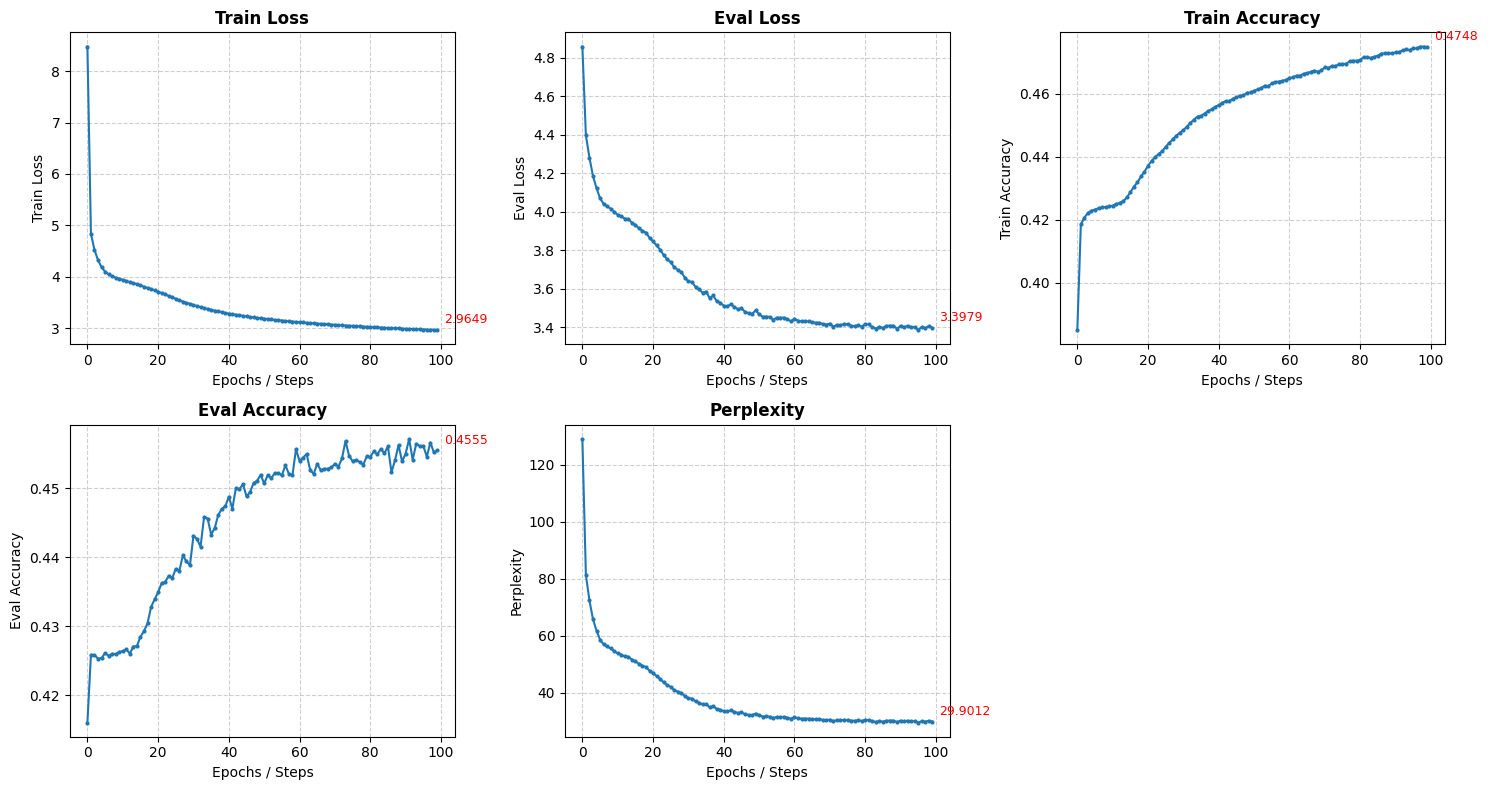

In [27]:
# Define the order of plotting and pretty titles
keys = ['train_loss', 'eval_loss', 'train_acc', 'eval_acc', 'perplexity']
titles = ['Train Loss', 'Eval Loss', 'Train Accuracy', 'Eval Accuracy', 'Perplexity']

# Create a 2x3 grid (2 rows, 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Flatten the 2D array of axes into a 1D array for easy looping
axes = axes.flatten()

for i, (key, title) in enumerate(zip(keys, titles)):
    ax = axes[i]
    
    # Plot the data (added small markers for easier visual tracking of epochs)
    ax.plot(results[key], marker='.', markersize=4, linewidth=1.5)
    
    # Formatting
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Epochs / Steps')
    ax.set_ylabel(title)
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # Optional: Highlight the final value
    if len(results[key]) > 0:
        final_val = results[key][-1]
        ax.annotate(f'{final_val:.4f}', 
                    xy=(len(results[key])-1, final_val), 
                    xytext=(5, 5), textcoords='offset points',
                    fontsize=9, color='red')

# Hide the 6th empty subplot
axes[-1].set_visible(False)

# Adjust layout to prevent overlapping labels
plt.tight_layout()
plt.show()